## Extracao dos dados

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
from scipy import stats
import json
import subprocess
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)


## Funcoes do pipeline


In [ ]:
def carregar_base(caminho, separador=","):
    return pd.read_csv(caminho, sep=separador)

def renomear_colunas(df, mapa):
    return df.rename(columns=mapa)

def mapear_colunas(df, mapas):
    df = df.copy()
    for coluna, mapa in mapas.items():
        df[coluna] = df[coluna].map(mapa)
    return df

def remover_colunas(df, colunas):
    return df.drop(columns=list(colunas))

def aplicar_one_hot(df, especificacoes):
    df = df.copy()
    dummies = []
    colunas_remover = []
    for coluna, mapa, prefixo in especificacoes:
        codificado = pd.get_dummies(df[coluna].map(mapa), prefix=prefixo).astype(int)
        dummies.append(codificado)
        colunas_remover.append(coluna)
    return pd.concat([df.drop(columns=colunas_remover), *dummies], axis=1)

def exibir_estrutura(df):
    df.info()
    return df.shape[0]

def diagnosticar_ausentes(df):
    print(df.isna().sum())
    return df[
        (df["meses_como_cliente"].isna())
        | (df["meses_como_cliente"] == 0)
    ]

def remover_clientes_sem_cobranca(df, quantidade_registros_iniciais):
    meses_como_cliente_igual_a_zero = df["meses_como_cliente"] == 0
    total_cobrado_numerico = pd.to_numeric(df["total_cobrado_durante_trimestre"], errors="coerce")
    total_cobrado_nulo_vazio_ou_zero = total_cobrado_numerico.isna() | (total_cobrado_numerico == 0)
    df = df[~(meses_como_cliente_igual_a_zero & total_cobrado_nulo_vazio_ou_zero)].copy()
    soma_de_registros_atuais = df.shape[0]
    print(f"Registros iniciais: {quantidade_registros_iniciais}, Registros atuais: {soma_de_registros_atuais}, Registros removidos: {quantidade_registros_iniciais - soma_de_registros_atuais}")
    df["total_cobrado_durante_trimestre"] = df["total_cobrado_durante_trimestre"].astype("float64")
    return df

def contar_addons(df, colunas, nome_coluna):
    df = df.copy()
    df[nome_coluna] = df[colunas].sum(axis=1)
    return df

def exibir_proporcao_target(df, textos_desbalanceado, texto_balanceado, coluna="target"):
    print("=== DISTRIBUICAO DA VARIAVEL TARGET ===\n")
    target_counts = df[coluna].value_counts()
    target_percentages = df[coluna].value_counts(normalize=True) * 100

    print("Contagem:")
    print(target_counts)
    print("\nPercentual:")
    for idx, pct in target_percentages.items():
        label = "Nao cancelou" if idx == 0 else "Cancelou"
        print(f"{label} ({idx}): {pct:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(['Nao cancelou', 'Cancelou'], target_counts.values, color=['lightblue', 'coral'])
    axes[0].set_ylabel('Frequencia')
    axes[0].set_title('Distribuicao da Variavel Target')
    axes[0].grid(axis='y', alpha=0.3)

    axes[1].pie(target_counts.values, labels=['Nao cancelou', 'Cancelou'],
                autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
    axes[1].set_title('Proporcao de Classes')

    plt.tight_layout()
    plt.show()

    ratio = target_counts.min() / target_counts.max()
    print(f"\nRatio de balanceamento: {ratio:.2f}")
    if ratio < 0.5:
        for texto in textos_desbalanceado:
            print(texto)
    else:
        print(texto_balanceado)

def descrever_colunas(df, colunas):
    return df[list(colunas)].describe().round(2)

def exibir_dispersao(df, colunas):
    n = len(colunas)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    axes = axes.ravel()

    for idx, col in enumerate(colunas):
        sns.boxplot(x=df[col], ax=axes[idx], color='coral')
        axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
        axes[idx].set_xlabel(col)
        axes[idx].grid(axis='x', alpha=0.3)

        col_zscore = np.abs(stats.zscore(df[col].dropna()))
        outlier_count = (col_zscore > 3).sum()
        axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                       transform=axes[idx].transAxes, fontsize=9,
                       verticalalignment='top', horizontalalignment='right',
                       bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

    for ax in axes[n:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

def dividir_treino_teste(df, test_size=0.3, random_state=42, estratificar=False, coluna_target="target"):
    X = df.drop(columns=[coluna_target])
    y = df[coluna_target]
    if estratificar:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state, stratify=y
        )
    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )
    print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")
    return X, y, X_train, X_test, y_train, y_test

def escalonar_colunas(X_train, X_test, colunas):
    escalonador = StandardScaler()
    X_train_escalonado = X_train.copy()
    X_test_escalonado = X_test.copy()
    X_train_escalonado[list(colunas)] = escalonador.fit_transform(X_train[list(colunas)])
    X_test_escalonado[list(colunas)] = escalonador.transform(X_test[list(colunas)])
    return X_train_escalonado, X_test_escalonado, escalonador

def aplicar_smote(X_train, y_train, random_state=42):
    smote = SMOTE(random_state=random_state)
    X_train_balanceado, y_train_balanceado = smote.fit_resample(X_train, y_train)
    print("Distribuicao antes do SMOTE:")
    print(y_train.value_counts())
    print("\nDistribuicao depois do SMOTE:")
    print(y_train_balanceado.value_counts())
    return X_train_balanceado, y_train_balanceado, smote

def calcular_metricas_classificacao(y_true, y_pred, y_proba):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1_score": f1_score(y_true, y_pred),
        "matriz_confusao": confusion_matrix(y_true, y_pred),
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

def exibir_metricas_classificacao(acuracia, precisao, recall, f1, roc_auc, matriz_confusao, prefixo=""):
    print(f"{prefixo}Acuracia: {acuracia:.4f}")
    print(f"Precisao: {precisao:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")
    print("Matriz de confusao:")
    print(matriz_confusao)

def salvar_metricas(metricas, diretorio):
    diretorio = Path(diretorio)
    diretorio.mkdir(parents=True, exist_ok=True)
    with open(diretorio / "metrics.json", "w") as arquivo_metricas:
        json.dump(metricas, arquivo_metricas, indent=4)

def exibir_matriz_e_roc(matriz_confusao, fpr, tpr, roc_auc, axes=None):
    criar_figura = axes is None
    if criar_figura:
        _, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title("Matriz de Confusao")

    axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc:.4f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_xlabel("Taxa de Falsos Positivos")
    axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
    axes[1].set_title("Curva ROC")
    axes[1].legend()

    if criar_figura:
        plt.tight_layout()
        plt.show()

def consultar_metricas_dvc(diretorio_projeto):
    resultado_dvc = subprocess.run(
        ["dvc", "metrics", "show"],
        cwd=diretorio_projeto,
        capture_output=True, text=True
    )
    print(resultado_dvc.stdout)
    print(resultado_dvc.stderr)
    return resultado_dvc


In [1]:
caminho_base = "C:\\Projetos\\FIAP\\Fase_1\\Tech_Challenge_Churn_Prediction\\data\\raw\\Telco-Customer-Churn.csv"
dataframe_de_churn_inicial = carregar_base(caminho_base)

dataframe_de_churn_inicial.head(n=100)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Transformacao de nomes de features para portugues

In [2]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_durante_trimestre",
    "Churn": "target",
}

dataframe_de_churn_inicial_colunas_traduzidas = renomear_colunas(dataframe_de_churn_inicial, colunas_pt_br)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)


,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Mudanca da variavel target para binaria

In [3]:
dataframe_de_churn_inicial_colunas_traduzidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_traduzidas,
    {"target": {"Yes": 1, "No": 0}},
)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)


,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Removendo features sensiveis

In [4]:
colunas_sensiveis_sem_relevancia_para_churn = ["id_cliente", "genero", "dependentes"]

dataframe_de_churn_inicial_colunas_sensiveis_removidas = remover_colunas(
    dataframe_de_churn_inicial_colunas_traduzidas,
    colunas_sensiveis_sem_relevancia_para_churn,
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Binarizando features categoricas deterministicas

In [5]:
mapas_binarios_deterministicos = {
    "casado": {"Yes": 1, "No": 0},
    "fatura_sem_papel": {"Yes": 1, "No": 0},
    "possui_servico_telefonico": {"Yes": 1, "No": 0},
}

dataframe_de_churn_inicial_colunas_sensiveis_removidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    mapas_binarios_deterministicos,
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,1,Electronic check,78.95,927.35,1
96,0,1,71,1,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,1,Credit card (automatic),66.85,4748.7,0
97,0,0,5,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,0,Mailed check,21.05,113.85,1
98,0,0,52,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,0,Bank transfer (automatic),21.00,1107.2,0


## Trabalhando com features binarias nao determinitiscas

In [6]:
mapas_binarios_nao_deterministicos = {
    "possui_seguranca_online": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_backup_online": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_protecao_dispositivo": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_suporte_tecnico_premium": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_streaming_tv_terceiros": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_streaming_filmes_terceiros": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_multiplas_linhas": {"Yes": 1, "No": 0, "No phone service": 0},
    "tipo_contrato": {"Month-to-month": 0, "One year": 1, "Two year": 2},
}

codigo_para_servico_de_internet = {"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"}
codigo_para_metodo_pagamento = {"Mailed check": "mailed_check", "Electronic check": "electronic_check", "Bank transfer (automatic)": "bank_transfer_automatic", "Credit card (automatic)": "credit_card_automatic"}

dataframe_de_churn_inicial_colunas_sensiveis_removidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    mapas_binarios_nao_deterministicos,
)
dataframe_de_churn_inicial_colunas_sensiveis_removidas = aplicar_one_hot(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    [
        ("possui_servico_de_internet", codigo_para_servico_de_internet, "possui_servico_de_internet"),
        ("metodo_pagamento", codigo_para_metodo_pagamento, "metodo_pagamento"),
    ],
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.5,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.7,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.2,0,0,0,1,1,0,0,0


## Informacoes estruturais

In [7]:
soma_de_registros_iniciais = exibir_estrutura(dataframe_de_churn_inicial_colunas_sensiveis_removidas)


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   cliente_em_idade_avancada                 7043 non-null   int64  
 1   casado                                    7043 non-null   int64  
 2   meses_como_cliente                        7043 non-null   int64  
 3   possui_servico_telefonico                 7043 non-null   int64  
 4   possui_multiplas_linhas                   7043 non-null   int64  
 5   possui_seguranca_online                   7043 non-null   int64  
 6   possui_backup_online                      7043 non-null   int64  
 7   possui_protecao_dispositivo               7043 non-null   int64  
 8   possui_suporte_tecnico_premium            7043 non-null   int64  
 9   possui_streaming_tv_terceiros             7043 non-null   int64  
 10  possui_streaming_filmes_terceiros         7043 

## Identificando Missing Values

In [8]:
dataframe_validacao_cenario_meses_como_cliente_zero = diagnosticar_ausentes(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas
)
dataframe_validacao_cenario_meses_como_cliente_zero.head(n=100)


cliente_em_idade_avancada                   0
casado                                      0
meses_como_cliente                          0
possui_servico_telefonico                   0
possui_multiplas_linhas                     0
possui_seguranca_online                     0
possui_backup_online                        0
possui_protecao_dispositivo                 0
possui_suporte_tecnico_premium              0
possui_streaming_tv_terceiros               0
possui_streaming_filmes_terceiros           0
tipo_contrato                               0
fatura_sem_papel                            0
cobranca_mensal                             0
total_cobrado_durante_trimestre             0
target                                      0
possui_servico_de_internet_dsl              0
possui_servico_de_internet_fibra_optica     0
possui_servico_de_internet_sem_internet     0
metodo_pagamento_bank_transfer_automatic    0
metodo_pagamento_credit_card_automatic      0
metodo_pagamento_electronic_check 

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,,0,1,0,0,0,0,0,1


## Removendo os Missing Values

In [9]:
dataframe_de_churn_missing_values_aplicado = remover_clientes_sem_cobranca(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    soma_de_registros_iniciais,
)
dataframe_de_churn_missing_values_aplicado.head(n=100)


Registros iniciais: 7043, Registros atuais: 7032, Registros removidos: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0


## Engenharia de features: contagem de addons contratados

In [10]:
colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
dataframe_de_churn_missing_values_aplicado = contar_addons(
    dataframe_de_churn_missing_values_aplicado,
    colunas_addons,
    "quantidade_de_addons",
)

dataframe_de_churn_missing_values_aplicado.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0,0


## Proporcao da variavel target

=== DISTRIBUICAO DA VARIAVEL TARGET ===

Contagem:
target
0    5163
1    1869
Name: count, dtype: int64

Percentual:
Nao cancelou (0): 73.42%
Cancelou (1): 26.58%


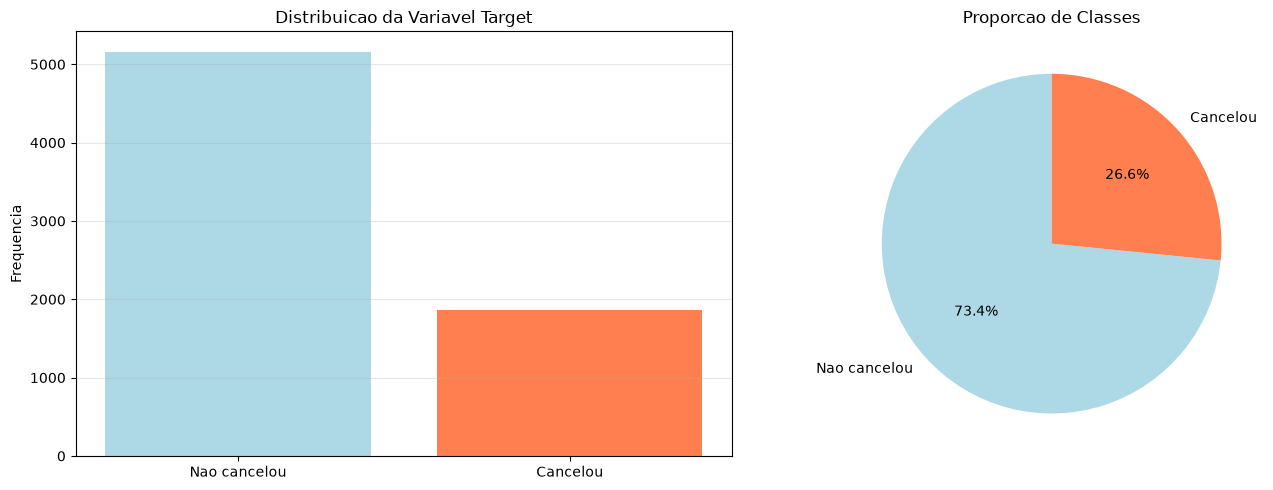


Ratio de balanceamento: 0.36
Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.


In [11]:
textos_desbalanceado = [
    "Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.",
]
texto_balanceado = "Dataset razoavelmente balanceado."

exibir_proporcao_target(
    dataframe_de_churn_missing_values_aplicado,
    textos_desbalanceado,
    texto_balanceado,
)


## Analise de dispersao das variaveis numericas em relacao a media

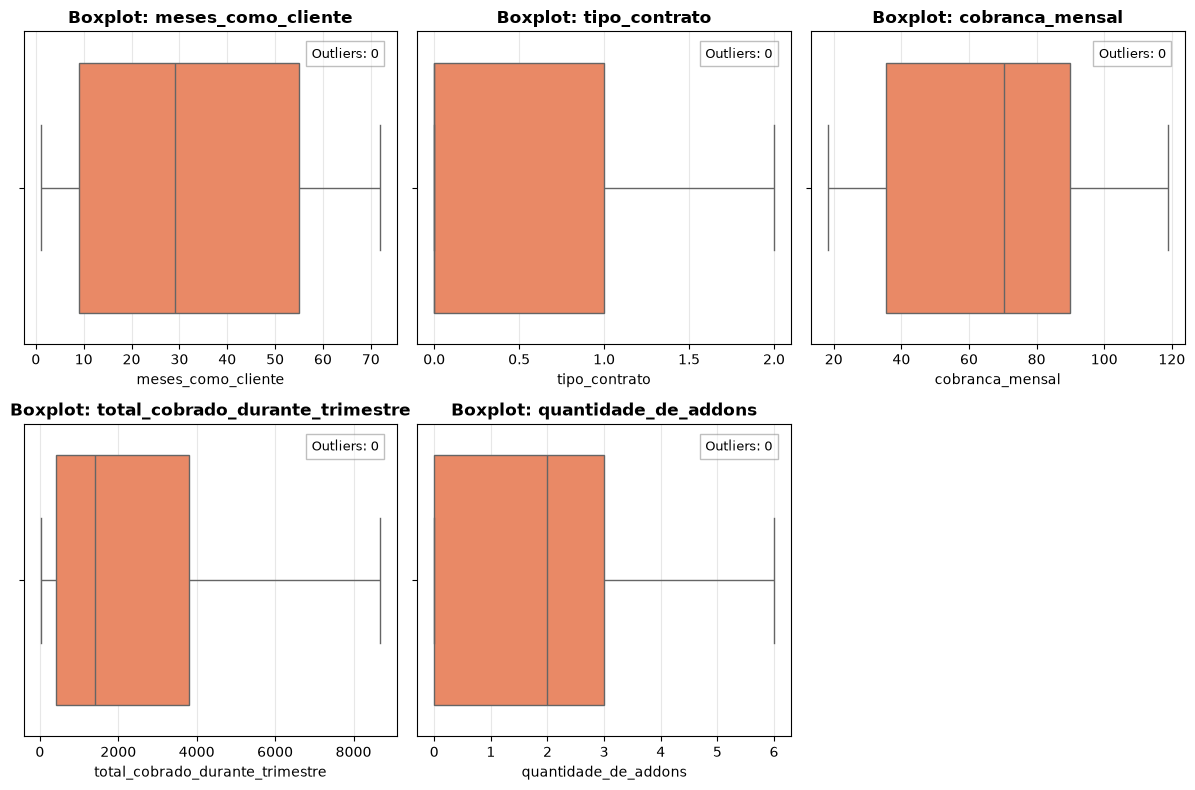

In [12]:
numeric_cols = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "total_cobrado_durante_trimestre", "quantidade_de_addons"]

exibir_dispersao(dataframe_de_churn_missing_values_aplicado, numeric_cols)


## Informacoes Estatisticas

In [13]:
colunas_para_describe = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "total_cobrado_durante_trimestre", "quantidade_de_addons"]

descrever_colunas(dataframe_de_churn_missing_values_aplicado, colunas_para_describe)


,meses_como_cliente,tipo_contrato,cobranca_mensal,total_cobrado_durante_trimestre,quantidade_de_addons
count,7032.00,7032.00,7032.00,7032.00,7032.00
mean,32.42,0.69,64.80,2283.30,2.04
std,24.55,0.83,30.09,2266.77,1.85
min,1.00,0.00,18.25,18.80,0.00
25%,9.00,0.00,35.59,401.45,0.00
50%,29.00,0.00,70.35,1397.48,2.00
75%,55.00,1.00,89.86,3794.74,3.00
max,72.00,2.00,118.75,8684.80,6.00


## Dividindo dados entre treino e teste

In [14]:
X, y, X_train, X_test, y_train, y_test = dividir_treino_teste(
    dataframe_de_churn_missing_values_aplicado,
    test_size=0.3,
    random_state=42,
    estratificar=True,
)


X_train: (4922, 23), X_test: (2110, 23), y_train: (4922,), y_test: (2110,)


## Redimensionando a escala dos dados antes do treino

In [15]:
colunas_para_escalonar = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "total_cobrado_durante_trimestre", "quantidade_de_addons"]

X_train_escalonado, X_test_escalonado, escalonador = escalonar_colunas(
    X_train, X_test, colunas_para_escalonar
)

X_train_escalonado.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
4499,0,0,-0.833469,1,1,1,0,0,0,0,0,-0.830368,1,0.444749,-0.607066,0,1,0,0,0,1,0,-0.565455
1933,0,0,-0.508058,1,0,0,0,0,0,0,0,0.363635,1,-1.492135,-0.823672,0,0,1,0,0,0,1,-1.107139
4668,0,0,-1.240233,1,0,1,0,0,0,0,1,-0.830368,1,-0.120451,-0.950975,1,0,0,0,1,0,0,-0.023772
5681,1,1,0.061411,1,0,0,0,1,1,1,0,0.363635,0,-0.021293,-0.081500,1,0,0,1,0,0,0,0.517912
3610,0,0,-0.833469,1,1,0,0,1,0,1,1,-0.830368,1,1.166949,-0.495086,0,1,0,1,0,0,0,0.517912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1750,0,0,0.712233,1,0,0,0,1,1,0,1,1.557638,1,0.821549,0.883622,0,1,0,1,0,0,0,0.517912
1736,0,0,-1.280909,1,0,0,0,0,0,0,0,-0.830368,0,-1.498746,-0.997712,0,0,1,0,0,0,1,-1.107139
5350,0,1,0.834262,1,1,1,1,0,0,0,1,1.557638,0,0.160497,0.612091,1,0,0,1,0,0,0,0.517912
219,0,0,-0.996174,1,0,0,0,0,0,1,0,-0.830368,1,0.500939,-0.732042,0,1,0,1,0,0,0,-0.565455


## Aplicando SMOTE para balanceamento entre as classes

In [16]:
X_train_balanceado, y_train_balanceado, smote = aplicar_smote(X_train_escalonado, y_train)


Distribuicao antes do SMOTE:
target
0    3614
1    1308
Name: count, dtype: int64

Distribuicao depois do SMOTE:
target
1    3614
0    3614
Name: count, dtype: int64


## Treinamento do modelo com SMOTE e registro de metricas no DVC

Acuracia: 0.7649
Precisao: 0.5433
Recall: 0.7273
F1-score: 0.6220
ROC AUC: 0.8351
Matriz de confusao:
[[1206  343]
 [ 153  408]]


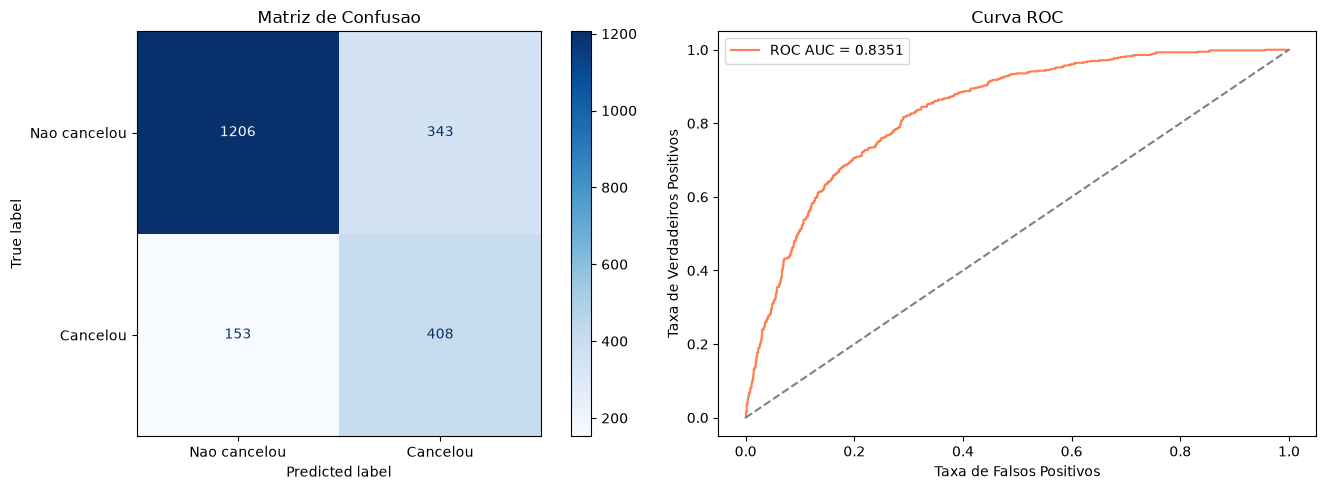

Path                                                          acuracia    f1_score    precisao    recall    roc_auc
notebooks\regressao_logistica\historico\metrics\metrics.json  0.76493     0.62195     0.54328     0.72727   0.83508




In [17]:
modelo_regressao_logistica = LogisticRegression(random_state=42, max_iter=1000)
modelo_regressao_logistica.fit(X_train_balanceado, y_train_balanceado)

y_pred = modelo_regressao_logistica.predict(X_test_escalonado)
y_proba = modelo_regressao_logistica.predict_proba(X_test_escalonado)[:, 1]

metricas_calculadas = calcular_metricas_classificacao(y_test, y_pred, y_proba)
acuracia = metricas_calculadas["acuracia"]
precisao = metricas_calculadas["precisao"]
recall = metricas_calculadas["recall"]
f1 = metricas_calculadas["f1_score"]
matriz_confusao = metricas_calculadas["matriz_confusao"]
fpr = metricas_calculadas["fpr"]
tpr = metricas_calculadas["tpr"]
roc_auc = metricas_calculadas["roc_auc"]

exibir_metricas_classificacao(acuracia, precisao, recall, f1, roc_auc, matriz_confusao)

metricas_dir = Path(r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\notebooks\regressao_logistica\historico\metrics")
metricas = {
    "acuracia": acuracia,
    "precisao": precisao,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "matriz_confusao": matriz_confusao.tolist(),
}

salvar_metricas(metricas, metricas_dir)

exibir_matriz_e_roc(matriz_confusao, fpr, tpr, roc_auc)

resultado_dvc = consultar_metricas_dvc(r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction")
